# Free Clinic of Powhatan: A1C Preliminary Analysis (Report 5.02a)

This notebook uses the 5.02a Lab Results Analysis Report from eCW. The report contains all lab results (CMP, CBC, lipids, and other tests). The first step is to keep only the A1C rows.

The notebook shows only aggregate counts. It does not show names, phone numbers, or account numbers. The saved outputs describe a small population, so keep them inside the clinic.

This notebook describes the data. It does not diagnose diabetes. It does not measure the effect of treatment. It does not set clinical targets.

The clinical cutpoints in Section 2 are provisional. They come from the ADA categories. The clinic must approve or replace them before you share the results.

Use the project `.venv` kernel. It has pandas, numpy, and matplotlib.

## 1. Imports

In [1]:
from pathlib import Path
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Chart colors
BLUE, BLUE_DARK, BLUE_LIGHT = "#2a78d6", "#104281", "#9ec5f4"
ORANGE = "#eb6834"
MUTED = "#a8a7a0"
INK, INK_2 = "#0b0b0b", "#52514e"

# Default plot style
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

## 2. Settings

Read this section before you run the notebook.

We checked these data settings against the 5.02a file on 2026-11-14:
- The file is UTF-16 and tab-separated. Each data row has an extra tab at the end. The loader corrects this.
- The A1C attributes are `Hemoglobin A1C` and `Hemoglobin A1c`. The match is not case-sensitive.
- We do not use `Est. Average Glucose`. It is calculated from the A1C. It is not a separate test.
- `B-2-Glycoprotein` contains the text "glyco", but it is a different test. We do not use it.
- All A1C values are between 3.8 and 21.8. These values agree with percent (NGSP) units. Values in mmol/mol (IFCC) are approximately 20 to 200. Thus, `UNITS_CONFIRMED_PERCENT = True`. Confirm the units with the clinic.

Analysis period: 2023-01-01 to 2026-11-14 (the export date). This is the full span of the export.

Provisional clinical cutpoints (the clinic must approve these):

| Setting | Default | Source |
|---|---|---|
| Prediabetes range | 5.7 to 6.4% | ADA diagnostic categories |
| Diabetes range | 6.5% or higher | ADA diagnostic categories |
| Control threshold | Less than 7.0% | ADA general goal for many adults who are not pregnant. The target can be different for each patient. |
| Meaningful change | 0.5 percentage points, up or down | Usual value for a clinically meaningful A1C change |

A lab export does not show which patients have a diabetes diagnosis. In this notebook, the "diabetes-range cohort" is the patients whose first A1C in the period was 6.5% or higher. This is an estimate from lab values. It is not a diagnosis.

In [2]:
INPUT_FILE = Path("data/5.02a - Lab Results Analysis Report.csv")
SHEET_NAME = 0
HEADER_ROW = 0
CSV_ENCODING = None            # None = find the encoding from the file (UTF-16 or UTF-8)
CSV_SEPARATOR = None           # None = find the separator from the header line

START_DATE = "2023-01-01"      # first date included; confirm with the clinic
END_DATE = "2026-11-14"        # last date included; this is the export date
UNITS_CONFIRMED_PERCENT = True # values are 3.8 to 21.8, so the units are percent
A1C_LABELS = {"Hemoglobin A1c"}   # not case-sensitive, so it also matches "Hemoglobin A1C"
A1C_SEARCH_PATTERN = r"a1c|hba1|glycated|glycosylated|glyco|average glucose"  # used only for the label check
ELIGIBLE_IDS_FILE = None       # optional: Path("data/eligible_patients.csv") with a patient_id column

COLUMN = {
    "patient_id": "patient_acct_no",
    "date": "order_collection_performed_date",
    "attribute": "lab_attribute",
    "value": "lab_attribute_value",
    "order_name": "order_name",
    "order_status": "order_status",
}
ID_COLUMNS = None              # None = combine all Patient Acct No columns

# Provisional clinical settings (ADA defaults). Replace them with values the clinic approves.
PREDIABETES_THRESHOLD = 5.7
DIABETES_RANGE_THRESHOLD = 6.5
CONTROL_THRESHOLD = 7.0
CONTROL_OPERATOR = "<"
STABILITY_TOLERANCE_PP = 0.5
BASELINE_BINS = [0, 5.7, 6.5, 8.0, 10.0, np.inf]
BASELINE_LABELS = ["<5.7", "5.7-6.4", "6.5-7.9", "8.0-9.9", ">=10.0"]
FOLLOWUP_WINDOW_DAYS = 183     # repeat test in approximately 6 months
REVIEW_HIGH_VALUE = 15.0       # list values above this for review (they stay in the data)
SETTINGS_ARE_PROVISIONAL = True

# Duplicates and exclusions
COLLAPSE_IDENTICAL_DUPLICATES = True  # same patient, same day, same value: keep one row
APPROVED_KEEP_DUPLICATE_ROWS = []     # source rows to keep when same-day values are different
MANUAL_EXCLUDE_ROWS = []              # use only for exclusions that a clinician approves
EXCLUSION_REASON = ""

OUTPUT_DIR = Path("outputs/5.02a")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_ROW_LEVEL_FILES = False   # row-level files contain account numbers and dates

EXPORT_NOTES = {
    "report": "5.02a Lab Results Analysis Report",
    "date_field": "Order Collection / Performed Date",
    "all_results": "All lab attributes; no numeric-range filter",
    "numeric_ranges": "none",
    "lab_status_active": "",
    "inhouse_labs": "Both (all A1C rows have InHouse Lab = No)",
    "other_filters": "",
    "cohort_definition": "Patients with 1 or more A1C in the period; diabetes-range cohort = first A1C >= 6.5",
    "units_confirmation": "Range check only (3.8 to 21.8); confirm with the clinic",
    "duplicate_resolution": "Same-day identical copies removed; same-day different values held for review",
}

## 3. Load the export

The eCW CSV export is UTF-16 and tab-separated. Each data row ends with an extra tab. Thus, the data rows have one more field than the header row. `index_col=False` stops pandas from using the first column as the index. If pandas uses it as the index, all the columns move one position to the left.

In [3]:
def normalized_name(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().lower()).strip("_")

def load_export(path, verbose=True):
    if not path.exists():
        raise FileNotFoundError(f"Put the export at {path.resolve()} or change INPUT_FILE.")
    if path.suffix.lower() in {".xlsx", ".xlsm"}:
        return pd.read_excel(path, sheet_name=SHEET_NAME, header=HEADER_ROW, dtype=str, engine="openpyxl")

    # Find the encoding from the first bytes of the file
    with path.open("rb") as handle:
        prefix = handle.read(4)
    encoding = CSV_ENCODING or ("utf-16" if prefix.startswith((b"\xff\xfe", b"\xfe\xff")) else "utf-8-sig")

    # Find the separator from the header line
    separator = CSV_SEPARATOR
    if separator is None:
        with path.open("r", encoding=encoding, newline="") as handle:
            lines = handle.read(65536).splitlines()
        header_line = lines[HEADER_ROW] if len(lines) > HEADER_ROW else ""
        counts = {d: header_line.count(d) for d in ("\t", ",", ";", "|")}
        separator = max(counts, key=counts.get)
        if counts[separator] == 0:
            raise ValueError("Set CSV_SEPARATOR to the separator in the file.")
    if verbose:
        print(f"{path.name}: encoding={encoding}, separator={separator!r}")

    frame = pd.read_csv(path, encoding=encoding, sep=separator, header=HEADER_ROW,
                        dtype=str, index_col=False)
    frame.columns = [normalized_name(c) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError("Two or more column names are the same after cleanup. Rename them first.")
    return frame

raw = load_export(INPUT_FILE)
missing = [c for c in COLUMN.values() if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Check HEADER_ROW and COLUMN.")

attr_all = raw[COLUMN["attribute"]].astype("string").str.strip()
print(f"Rows: {len(raw):,}")
print(f"Lab attributes: {attr_all.nunique():,}   orders: {raw[COLUMN['order_name']].nunique():,}")
print(f"Patients (any lab): {raw[COLUMN['patient_id']].nunique():,}")
print("Columns:", raw.columns.tolist())
print("\nMost common lab attributes:")
display(attr_all.value_counts().head(12).rename_axis("lab_attribute").to_frame("rows"))

5.02a - Lab Results Analysis Report.csv: encoding=utf-16, separator='\t'


Rows: 55,364
Lab attributes: 466   orders: 270
Patients (any lab): 596
Columns: ['patient_acct_no', 'none', 'none_1', 'none_2', 'practice_name', 'encounter_date', 'order_collection_performed_date', 'appointment_facility_name', 'appointment_facility_pos', 'patient_acct_no_1', 'patient_name', 'actual_fasting', 'order_priority', 'order_name', 'order_status', 'approval_required', 'inhouse_lab', 'lab_attribute', 'lab_attribute_value', 'order_result', 'aoe_question', 'aoe_answer', 'aoe_lab_company_id', 'aoe_lab_company_name', 'count_distinct_patient_acct_no', 'count_distinct_patient_acct_no_1', 'count_distinct_patient_acct_no_2', 'count_distinct_patient_acct_no_3']

Most common lab attributes:


,rows
lab_attribute,
BUN,1383
Triglycerides,1220
Hemoglobin,1161
GLUCOSE,1139
WBC,1131
Hematocrit,1129
MCV,1129
Potassium,1061
Creatinine,1057


## 4. Filter to A1C rows

### 4a. Label check

A loose text search finds all attribute names and order names that can be A1C. Use this table to check the labels in `A1C_LABELS`.

The notebook keeps only the rows where the Lab Attribute is an exact match to a label in `A1C_LABELS`. The match ignores case and extra spaces. An exact match is necessary for two reasons:
- A loose search for "hemoglobin" also finds the CBC hemoglobin test.
- The "with EAG" order also has an "Est. Average Glucose" row. That value is calculated from the A1C. It is not a separate test.

In [4]:
order_all = raw[COLUMN["order_name"]].astype("string").str.strip()

# Loose search, used only to show the possible A1C labels
candidate = (attr_all.str.contains(A1C_SEARCH_PATTERN, case=False, na=False)
             | order_all.str.contains(A1C_SEARCH_PATTERN, case=False, na=False))

# Exact match, used to select the A1C rows
labels = {x.strip().casefold() for x in A1C_LABELS}
selected = attr_all.str.casefold().isin(labels).fillna(False)

label_audit = (pd.DataFrame({"lab_attribute": attr_all[candidate], "order_name": order_all[candidate]})
               .value_counts().rename("rows").reset_index())
label_audit["kept_as_A1C"] = label_audit["lab_attribute"].str.casefold().isin(labels)
display(label_audit.sort_values(["kept_as_A1C", "rows"], ascending=[False, False]).reset_index(drop=True))
print(f"A1C rows: {int(selected.sum()):,} of {len(raw):,} rows ({100 * selected.mean():.1f}%)")

,lab_attribute,order_name,rows,kept_as_A1C
0,Hemoglobin A1C,Hemoglobin A1C with EAG,853,True
1,Hemoglobin A1c,Hemoglobin A1c,250,True
2,Hemoglobin A1C,Hemoglobin A1C,44,True
3,Est. Average Glucose,Hemoglobin A1C with EAG,841,False
4,B-2-Glycoprotein IgM,Beta-2-Glycoprotein Abs,1,False
5,B-2-Glycoprotein IgG,Beta-2-Glycoprotein Abs,1,False


A1C rows: 1,147 of 55,364 rows (2.1%)


### 4b. Make the A1C table

The export has more than one Patient Acct No column. The notebook combines them into one ID for each row. If the columns do not agree, the row gets a flag.

Some results are not plain numbers, for example `>14.0`, `6.3.`, and `Clotted sample`. The notebook does not change these to numbers. They go to the review log.

In [5]:
def clean_id(series):
    return (series.astype("string").str.strip()
            .str.replace(r"\.0$", "", regex=True).replace("", pd.NA))

id_columns = ID_COLUMNS or [
    c for c in raw.columns
    if c == COLUMN["patient_id"] or re.fullmatch(re.escape(COLUMN["patient_id"]) + r"_\d+", c)
]
ids = pd.concat([clean_id(raw[c]).rename(c) for c in id_columns], axis=1)

work = pd.DataFrame({
    "source_row": np.arange(1, len(raw) + 1),
    "patient_id": ids.bfill(axis=1).iloc[:, 0],
    "id_conflict": ids.nunique(axis=1, dropna=True).gt(1),
    "date_text": raw[COLUMN["date"]].astype("string").str.strip(),
    "attribute": attr_all,
    "order_name": order_all,
    "order_status": raw[COLUMN["order_status"]].astype("string").str.strip(),
    "value_text": raw[COLUMN["value"]].astype("string").str.strip(),
})
work = work[selected.to_numpy()].copy()
if work.empty:
    raise ValueError("No A1C labels matched. Check the label table and A1C_LABELS.")
work["date"] = pd.to_datetime(work["date_text"], format="mixed", errors="coerce").dt.normalize()

# Change only plain numbers (for example "7.2" or "7.2%") to numeric values
number_pattern = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)\s*%?"
plain_numeric = work["value_text"].str.fullmatch(number_pattern, na=False)
work["a1c"] = pd.to_numeric(
    work["value_text"].where(plain_numeric).str.replace("%", "", regex=False).str.strip(),
    errors="coerce")

eligible_ids = None
if ELIGIBLE_IDS_FILE is not None:
    eligible_ids = set(clean_id(pd.read_csv(ELIGIBLE_IDS_FILE, dtype=str)["patient_id"]).dropna())
    work = work[work["patient_id"].isin(eligible_ids)].copy()
scope = ("Eligible-patient list from the clinic" if eligible_ids is not None
         else "Patients with 1 or more A1C in this export; diabetes diagnosis not known")
print("Scope:", scope)
print(f"A1C rows: {len(work):,}   patients: {work['patient_id'].nunique():,}")
print("Order status:", work["order_status"].value_counts().to_dict())
numeric = work["a1c"].dropna()
print(f"Numeric A1C values: {len(numeric):,}; range {numeric.min()} to {numeric.max()}, median {numeric.median()}")
if UNITS_CONFIRMED_PERCENT and not numeric.between(2, 25).all():
    print("WARNING: some values are outside 2 to 25. Check the units again.")

Scope: Patients with 1 or more A1C in this export; diabetes diagnosis not known
A1C rows: 1,147   patients: 520
Order status: {'Reviewed': 1141, 'Open': 6}
Numeric A1C values: 1,143; range 3.8 to 21.8, median 5.7


## 5. Check for missing data, dates, and duplicates

The 0 to 100 check makes sure that each value is a possible percent. It is not a clinical rule for outliers. Values above `REVIEW_HIGH_VALUE` stay in the data, but the notebook lists them for review.

Same-day duplicates:
- Sometimes a patient has two or more A1C rows on the same date with the same value. Usually, this is one result that was filed two times. The notebook keeps one copy (`COLLAPSE_IDENTICAL_DUPLICATES`).
- If the values on the same date are different, the notebook holds the rows. They stay out until someone approves one row to keep.

In [6]:
start, end = pd.Timestamp(START_DATE).normalize(), pd.Timestamp(END_DATE).normalize()
if not UNITS_CONFIRMED_PERCENT:
    raise ValueError("Confirm that all values are in percent, then set UNITS_CONFIRMED_PERCENT = True.")
if start > end:
    raise ValueError("START_DATE must be on or before END_DATE.")
if MANUAL_EXCLUDE_ROWS and not EXCLUSION_REASON.strip():
    raise ValueError("Write the reason for the manual exclusions in EXCLUSION_REASON.")

# One flag column for each problem. A row with any flag is removed.
flags = pd.DataFrame(index=work.index)
flags["missing_id"] = work["patient_id"].isna()
flags["conflicting_id_columns"] = work["id_conflict"]
flags["missing_or_invalid_date"] = work["date"].isna()
flags["missing_or_non_plain_numeric_result"] = work["a1c"].isna()
flags["outside_analysis_period"] = work["date"].notna() & ~work["date"].between(start, end)
flags["outside_percent_scale"] = work["a1c"].notna() & ~work["a1c"].between(0, 100)
flags["manual_exclusion"] = work["source_row"].isin(MANUAL_EXCLUDE_ROWS)

# Same-day groups
valid_mask = ~flags.any(axis=1)
valid = work.loc[valid_mask].sort_values(["patient_id", "date", "source_row"])
grp = valid.groupby(["patient_id", "date"])["a1c"]
group_size, group_values = grp.transform("size"), grp.transform("nunique")
identical_group = group_size.gt(1) & group_values.eq(1)
conflicting_group = group_size.gt(1) & group_values.gt(1)
is_later_copy = valid.duplicated(["patient_id", "date"], keep="first")

flags["identical_same_day_copy"] = False
flags["conflicting_same_day_pending"] = False
if COLLAPSE_IDENTICAL_DUPLICATES:
    flags.loc[valid.index[identical_group & is_later_copy], "identical_same_day_copy"] = True
else:
    conflicting_group = conflicting_group | identical_group
pending = conflicting_group & ~valid["source_row"].isin(APPROVED_KEEP_DUPLICATE_ROWS)
flags.loc[valid.index[pending], "conflicting_same_day_pending"] = True

clean = work.loc[~flags.any(axis=1)].copy().sort_values(["patient_id", "date", "source_row"])
if clean.duplicated(["patient_id", "date"]).any():
    raise ValueError("A patient has more than one result on the same date. Approve one row to keep.")

review_log = work[["source_row", "patient_id", "date_text", "attribute", "value_text"]].join(flags)
review_log = review_log.loc[flags.any(axis=1)].copy()
cleaning_counts = flags.sum().astype(int).rename_axis("issue").to_frame("flagged_rows")
print("A row can have more than one flag. Do not add these counts together.")
display(cleaning_counts)

print("Results that are not plain numbers (removed, check the source):")
display(work.loc[flags["missing_or_non_plain_numeric_result"], "value_text"]
        .fillna("(blank)").value_counts().rename_axis("result_text").to_frame("rows"))
high = clean.loc[clean["a1c"].gt(REVIEW_HIGH_VALUE), "a1c"]
print(f"Values above {REVIEW_HIGH_VALUE}% to check in the chart (kept): {sorted(high.tolist())}")
print(f"\nA1C rows: {len(work):,}   kept: {len(clean):,}   removed: {len(work) - len(clean):,}")
print(f"Same-day groups: {int((identical_group & ~is_later_copy).sum())} identical (one copy kept), "
      f"{int((conflicting_group & ~is_later_copy).sum())} with different values (held)")
print(f"A1C range kept: {clean['a1c'].min()} to {clean['a1c'].max()}%; "
      f"dates {clean['date'].min().date()} to {clean['date'].max().date()}")

A row can have more than one flag. Do not add these counts together.


,flagged_rows
issue,
missing_id,0
conflicting_id_columns,0
missing_or_invalid_date,0
missing_or_non_plain_numeric_result,4
outside_analysis_period,0
outside_percent_scale,0
manual_exclusion,0
identical_same_day_copy,17
conflicting_same_day_pending,0


Results that are not plain numbers (removed, check the source):


,rows
result_text,
sample clotted,1
Clotted sample,1
6.3.,1
>14.0,1


Values above 15.0% to check in the chart (kept): [15.8, 21.8]

A1C rows: 1,147   kept: 1,126   removed: 21
Same-day groups: 17 identical (one copy kept), 0 with different values (held)
A1C range kept: 3.8 to 21.8%; dates 2023-01-05 to 2026-11-12


## 6. Testing volume and frequency

This section shows how many A1C tests the clinic does and how often patients get a repeat test. The export ends on 2026-11-14, so 2026 is not a full year.

In [7]:
clean["year"] = clean["date"].dt.year
volume = clean.groupby("year").agg(a1c_tests=("a1c", "size"), patients_tested=("patient_id", "nunique"))
first_year = clean.groupby("patient_id")["year"].min()
volume["patients_first_tested_this_year"] = first_year.value_counts().reindex(volume.index, fill_value=0)

# Months of data in each year (2026 is not complete)
volume["months_covered"] = [
    ((min(end, pd.Timestamp(f"{y}-12-31")) - max(start, pd.Timestamp(f"{y}-01-01"))).days + 1) / 30.44
    for y in volume.index]
volume["months_covered"] = volume["months_covered"].round(1)
display(volume)

tests_per_patient = clean.groupby("patient_id").size()
tpp = pd.cut(tests_per_patient, [0, 1, 2, 3, 5, np.inf], labels=["1", "2", "3", "4-5", "6+"])
tests_per_patient_table = tpp.value_counts().sort_index().rename_axis("A1C tests in period").to_frame("patients")
tests_per_patient_table["percent"] = (100 * tests_per_patient_table["patients"] / len(tests_per_patient)).round(1)
display(tests_per_patient_table)

gaps = clean.groupby("patient_id")["date"].diff().dt.days.dropna()
print(f"Days between tests for the same patient: median {gaps.median():.0f}, "
      f"IQR {gaps.quantile(.25):.0f} to {gaps.quantile(.75):.0f}, n = {len(gaps):,}")

,a1c_tests,patients_tested,patients_first_tested_this_year,months_covered
year,,,,
2023,186,151,151,12.0
2024,273,197,130,12.0
2025,273,195,81,12.0
2026,394,282,157,10.4


,patients,percent
A1C tests in period,,
1,265,51.1
2,118,22.7
3,55,10.6
4-5,51,9.8
6+,30,5.8


Days between tests for the same patient: median 175, IQR 105 to 273, n = 607


## 7. Follow-up and starting levels

- The baseline is the first A1C for each patient in this export. It is not always the date of diagnosis or the start of care.
- A paired patient has A1C results on two or more different dates.
- The starting-level groups use `BASELINE_BINS`. Each group includes its lower limit and excludes its upper limit.

In [8]:
# One row for each patient: first and latest A1C
grouped = clean.groupby("patient_id", sort=True)
patients = grouped.head(1).set_index("patient_id")[["date", "a1c"]].rename(
    columns={"date": "baseline_date", "a1c": "baseline_a1c"}).join(
    grouped.tail(1).set_index("patient_id")[["date", "a1c"]].rename(
        columns={"date": "latest_date", "a1c": "latest_a1c"}))
patients["n_dates"] = grouped["date"].nunique()
patients["max_a1c"] = grouped["a1c"].max()
patients["followup_days"] = (patients["latest_date"] - patients["baseline_date"]).dt.days
patients["change_pp"] = (patients["latest_a1c"] - patients["baseline_a1c"]).round(10)
cut = lambda s: pd.cut(s, bins=BASELINE_BINS, labels=BASELINE_LABELS, right=False)
patients["baseline_group"] = cut(patients["baseline_a1c"])
patients["latest_group"] = cut(patients["latest_a1c"])
patients["diabetes_range_at_baseline"] = patients["baseline_a1c"].ge(DIABETES_RANGE_THRESHOLD)

paired = patients.loc[(patients["n_dates"] >= 2) & (patients["followup_days"] > 0)].copy()
dm = patients.loc[patients["diabetes_range_at_baseline"]]
dm_paired = paired.loc[paired["diabetes_range_at_baseline"]]

coverage = {
    "results_kept": len(clean),
    "patients_with_1_or_more_results": len(patients),
    "patients_with_1_test_date": int(patients["n_dates"].eq(1).sum()),
    "paired_patients (2 or more test dates)": len(paired),
    "median_followup_days (paired)": paired["followup_days"].median(),
    "diabetes_range_cohort (first A1C >= 6.5)": len(dm),
    "diabetes_range_cohort_paired": len(dm_paired),
}
if eligible_ids is not None:
    coverage["eligible_patients_with_no_A1C"] = len(eligible_ids - set(patients.index))
coverage_table = pd.Series(coverage, name="value").rename_axis("metric").to_frame()
display(coverage_table)

baseline_distribution = patients.groupby("baseline_group", observed=False).agg(
    patients=("baseline_a1c", "size"),
    paired_patients=("n_dates", lambda s: int(s.ge(2).sum())),
    median_baseline_A1C=("baseline_a1c", "median"),
)
baseline_distribution["percent_of_patients"] = (100 * baseline_distribution["patients"] / len(patients)).round(1)
baseline_distribution["percent_with_repeat_test"] = (
    100 * baseline_distribution["paired_patients"] / baseline_distribution["patients"]).round(1)
display(baseline_distribution)

,value
metric,
results_kept,1126.0
patients_with_1_or_more_results,519.0
patients_with_1_test_date,265.0
paired_patients (2 or more test dates),254.0
median_followup_days (paired),411.5
diabetes_range_cohort (first A1C >= 6.5),67.0
diabetes_range_cohort_paired,54.0


,patients,paired_patients,median_baseline_A1C,percent_of_patients,percent_with_repeat_test
baseline_group,,,,,
<5.7,324,131,5.3,62.4,40.4
5.7-6.4,128,69,5.85,24.7,53.9
6.5-7.9,27,20,7.4,5.2,74.1
8.0-9.9,15,11,8.8,2.9,73.3
>=10.0,25,23,11.2,4.8,92.0


## 8. Change from first to latest A1C

The change is the latest A1C minus the first A1C, in percentage points (pp). Most patients are in the normal range. Thus, a summary of all patients hides the changes in patients with high values. The tables show the results for each starting level and for the diabetes-range cohort.

With the provisional 0.5 pp tolerance:
- Decreased: the change is less than -0.5 pp.
- Stable: the change is between -0.5 and +0.5 pp.
- Increased: the change is more than +0.5 pp.

Part of the decrease in patients who start high is regression to the mean. Thus, the differences between groups are descriptive. They do not show the effect of treatment.

In [9]:
tol = float(STABILITY_TOLERANCE_PP)

def change_summary(p):
    return pd.Series({
        "paired_patients": len(p),
        "median_baseline_A1C": p["baseline_a1c"].median(),
        "median_latest_A1C": p["latest_a1c"].median(),
        "mean_change_pp": p["change_pp"].mean(),
        "median_change_pp": p["change_pp"].median(),
        "change_IQR_low": p["change_pp"].quantile(.25),
        "change_IQR_high": p["change_pp"].quantile(.75),
        f"pct_decreased_>{tol}": 100 * p["change_pp"].lt(-tol).mean(),
        f"pct_stable_within_{tol}": 100 * p["change_pp"].abs().le(tol).mean(),
        f"pct_increased_>{tol}": 100 * p["change_pp"].gt(tol).mean(),
        "median_followup_days": p["followup_days"].median(),
    })

descriptive = pd.DataFrame({
    "All paired patients": change_summary(paired),
    "Diabetes-range cohort (first A1C >= 6.5)": change_summary(dm_paired),
    "First A1C >= 8.0": change_summary(paired[paired["baseline_a1c"].ge(8)]),
}).round(2)
display(descriptive)

baseline_comparison = paired.groupby("baseline_group", observed=False).apply(change_summary).round(2)
display(baseline_comparison)

transition = pd.crosstab(paired["baseline_group"], paired["latest_group"], margins=True,
                         margins_name="Total", dropna=False)
transition.index.name, transition.columns.name = "first A1C group", "latest A1C group"
print("Paired patients: first A1C group compared to latest A1C group (counts)")
display(transition)

,All paired patients,Diabetes-range cohort (first A1C >= 6.5),First A1C >= 8.0
paired_patients,254.00,54.00,34.00
median_baseline_A1C,5.60,8.95,10.65
median_latest_A1C,5.80,7.40,7.80
mean_change_pp,-0.21,-1.52,-2.31
median_change_pp,0.00,-0.80,-1.50
change_IQR_low,-0.20,-2.12,-3.70
change_IQR_high,0.20,-0.20,-0.28
pct_decreased_>0.5,14.17,62.96,70.59
pct_stable_within_0.5,77.56,22.22,20.59
pct_increased_>0.5,8.27,14.81,8.82


,paired_patients,median_baseline_A1C,median_latest_A1C,mean_change_pp,median_change_pp,change_IQR_low,change_IQR_high,pct_decreased_>0.5,pct_stable_within_0.5,pct_increased_>0.5,median_followup_days
baseline_group,,,,,,,,,,,
<5.7,131.0,5.40,5.4,0.13,0.10,-0.05,0.30,0.00,94.66,5.34,476.0
5.7-6.4,69.0,5.90,5.9,0.17,0.10,-0.10,0.20,2.90,88.41,8.70,364.0
6.5-7.9,20.0,7.35,6.6,-0.20,-0.55,-0.92,0.18,50.00,25.00,25.00,275.0
8.0-9.9,11.0,8.50,7.8,-0.75,-0.70,-1.50,-0.35,63.64,27.27,9.09,385.0
>=10.0,23.0,11.20,8.3,-3.05,-3.10,-4.25,-0.45,73.91,17.39,8.70,511.0


Paired patients: first A1C group compared to latest A1C group (counts)


latest A1C group,<5.7,5.7-6.4,6.5-7.9,8.0-9.9,>=10.0,Total
first A1C group,,,,,,
<5.7,101,29,1,0,0,131
5.7-6.4,8,55,4,1,1,69
6.5-7.9,1,9,5,4,1,20
8.0-9.9,0,0,7,3,1,11
>=10.0,0,4,7,3,9,23
Total,110,97,24,11,12,254


## 9. Control, progression, and repeat testing

- Control: an A1C less than 7.0% (provisional). The notebook checks control only in the diabetes-range cohort.
- Time to control: this starts with the patients whose first A1C was 7.0% or higher. The event is the first later result less than 7.0%. The tests do not occur at regular intervals. Thus, the true date of control is at some time between two tests.
- The Kaplan-Meier estimate is exploratory. A patient who does not reach control is censored at their last A1C.
- The median time to control applies only to the patients who reached control. Do not use it as a figure for all patients.
- Prediabetes range: this starts with the patients whose first A1C was 5.7 to 6.4%. It counts the patients who later had a result of 6.5% or higher. It also counts the patients whose latest result was less than 5.7%.
- Repeat testing: this is the percentage of the diabetes-range cohort with a second test within `FOLLOWUP_WINDOW_DAYS`. The ADA Standards of Care recommend an A1C test at least two times each year for patients who meet their goal. For other patients, they recommend a test each quarter.

In [10]:
threshold = float(CONTROL_THRESHOLD)
is_controlled = (lambda s: s.lt(threshold)) if CONTROL_OPERATOR == "<" else (lambda s: s.le(threshold))

# Time to first observed control
initially_uncontrolled = patients.loc[~is_controlled(patients["baseline_a1c"])].copy()
later = clean.join(patients[["baseline_date"]], on="patient_id")
hits = later.loc[later["patient_id"].isin(initially_uncontrolled.index)
                 & later["date"].gt(later["baseline_date"]) & is_controlled(later["a1c"])
                 ].groupby("patient_id")["date"].min()
time_to_control = initially_uncontrolled[["baseline_date", "latest_date", "followup_days", "n_dates"]].copy()
time_to_control["first_observed_control_date"] = hits.reindex(time_to_control.index)
time_to_control["control_observed"] = time_to_control["first_observed_control_date"].notna()
time_to_control["time_days"] = np.where(
    time_to_control["control_observed"],
    (time_to_control["first_observed_control_date"] - time_to_control["baseline_date"]).dt.days,
    time_to_control["followup_days"])

def kaplan_meier(t, event):
    df = pd.DataFrame({"t": t, "e": event.astype(int)}).sort_values("t")
    times = np.sort(df.loc[df["e"].eq(1), "t"].unique())
    surv, rows = 1.0, [(0, 0.0, len(df))]
    for u in times:
        at_risk = int((df["t"] >= u).sum())
        d = int(((df["t"] == u) & df["e"].eq(1)).sum())
        surv *= 1 - d / at_risk
        rows.append((u, 1 - surv, at_risk))
    return pd.DataFrame(rows, columns=["days", "cumulative_pct_reached_control", "at_risk"]).assign(
        cumulative_pct_reached_control=lambda x: 100 * x["cumulative_pct_reached_control"])

km = kaplan_meier(time_to_control["time_days"], time_to_control["control_observed"])

def km_at(day):
    return float(km.loc[km["days"].le(day), "cumulative_pct_reached_control"].iloc[-1])

at_risk_at = lambda day: int(time_to_control["time_days"].ge(day).sum())

n_initial = len(time_to_control)
n_reached = int(time_to_control["control_observed"].sum())
n_with_later_test = int(time_to_control["n_dates"].ge(2).sum())
control_metrics = pd.Series({
    "cohort_patients": len(dm),
    "cohort_latest_controlled": int(is_controlled(dm["latest_a1c"]).sum()),
    "cohort_latest_controlled_pct": 100 * is_controlled(dm["latest_a1c"]).mean(),
    "cohort_paired_patients": len(dm_paired),
    "cohort_paired_latest_controlled_pct": 100 * is_controlled(dm_paired["latest_a1c"]).mean(),
    "first_A1C_7_or_higher": n_initial,
    "first_A1C_7_or_higher_no_later_test": int(time_to_control["n_dates"].eq(1).sum()),
    "first_A1C_7_or_higher_later_controlled": n_reached,
    "later_controlled_pct_of_all": 100 * n_reached / n_initial if n_initial else np.nan,
    "later_controlled_pct_with_later_test": 100 * n_reached / n_with_later_test if n_with_later_test else np.nan,
    "median_days_to_control (only patients who reached it)":
        time_to_control.loc[time_to_control["control_observed"], "time_days"].median(),
    "KM_pct_controlled_by_180d (exploratory)": km_at(180),
    "still_followed_at_180d": at_risk_at(180),
    "KM_pct_controlled_by_365d (exploratory)": km_at(365),
    "still_followed_at_365d": at_risk_at(365),
    "still_followed_at_730d (too few for a 2-year estimate)": at_risk_at(730),
}, name="value").rename_axis("metric").to_frame().round(1)
display(control_metrics)

# Prediabetes range: later results
pre = paired.loc[paired["baseline_a1c"].ge(PREDIABETES_THRESHOLD) & paired["baseline_a1c"].lt(DIABETES_RANGE_THRESHOLD)]
later_vals = later.loc[later["date"].gt(later["baseline_date"])]
reached_dm = later_vals.loc[later_vals["a1c"].ge(DIABETES_RANGE_THRESHOLD)].groupby("patient_id").size()
prediabetes_progression = pd.Series({
    "paired_patients_first_A1C_5.7_to_6.4": len(pre),
    "later_result_>=6.5_count": int(pre.index.isin(reached_dm.index).sum()),
    "later_result_>=6.5_pct": 100 * pre.index.isin(reached_dm.index).mean(),
    "latest_result_<5.7_count": int(pre["latest_a1c"].lt(PREDIABETES_THRESHOLD).sum()),
    "latest_result_<5.7_pct": 100 * pre["latest_a1c"].lt(PREDIABETES_THRESHOLD).mean(),
    "median_followup_days": pre["followup_days"].median(),
}, name="value").rename_axis("metric").to_frame().round(1)
display(prediabetes_progression)

# Repeat testing in the diabetes-range cohort.
# Use only patients whose first test was early enough to see a repeat test in the window.
second = clean.join(patients[["baseline_date"]], on="patient_id")
second = second.loc[second["date"].gt(second["baseline_date"])].groupby("patient_id")["date"].min()
dm_days_to_second = (second.reindex(dm.index) - dm["baseline_date"]).dt.days
eligible_window = dm["baseline_date"].le(end - pd.Timedelta(days=FOLLOWUP_WINDOW_DAYS))
repeat_testing = pd.Series({
    "cohort_patients": len(dm),
    f"first_test_{FOLLOWUP_WINDOW_DAYS}d_or_more_before_end": int(eligible_window.sum()),
    f"retested_within_{FOLLOWUP_WINDOW_DAYS}d_pct":
        100 * dm_days_to_second[eligible_window].le(FOLLOWUP_WINDOW_DAYS).mean(),
    "ever_retested_pct": 100 * dm_days_to_second[eligible_window].notna().mean(),
    "median_days_to_second_test (retested only)": dm_days_to_second.median(),
}, name="value").rename_axis("metric").to_frame().round(1)
display(repeat_testing)

,value
metric,
cohort_patients,67.0
cohort_latest_controlled,21.0
cohort_latest_controlled_pct,31.3
cohort_paired_patients,54.0
cohort_paired_latest_controlled_pct,35.2
first_A1C_7_or_higher,58.0
first_A1C_7_or_higher_no_later_test,11.0
first_A1C_7_or_higher_later_controlled,23.0
later_controlled_pct_of_all,39.7


,value
metric,
paired_patients_first_A1C_5.7_to_6.4,69.0
later_result_>=6.5_count,9.0
later_result_>=6.5_pct,13.0
latest_result_<5.7_count,8.0
latest_result_<5.7_pct,11.6
median_followup_days,364.0


,value
metric,
cohort_patients,67.0
first_test_183d_or_more_before_end,55.0
retested_within_183d_pct,70.9
ever_retested_pct,89.1
median_days_to_second_test (retested only),111.5


## 10. Charts

These charts are for internal review.

The trajectory chart shows a random sample of diabetes-range patients (fixed seed). The x-axis shows the days since the first test, not calendar dates. The charts do not show identifiers. But small groups can make it possible to identify a patient. Do a review before you share the charts outside the clinic.

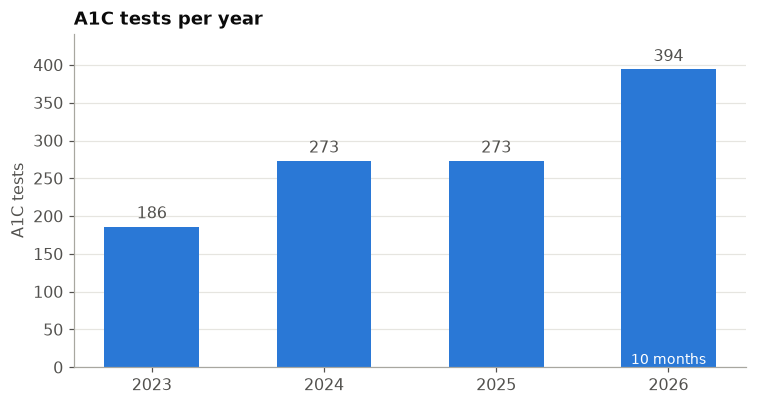

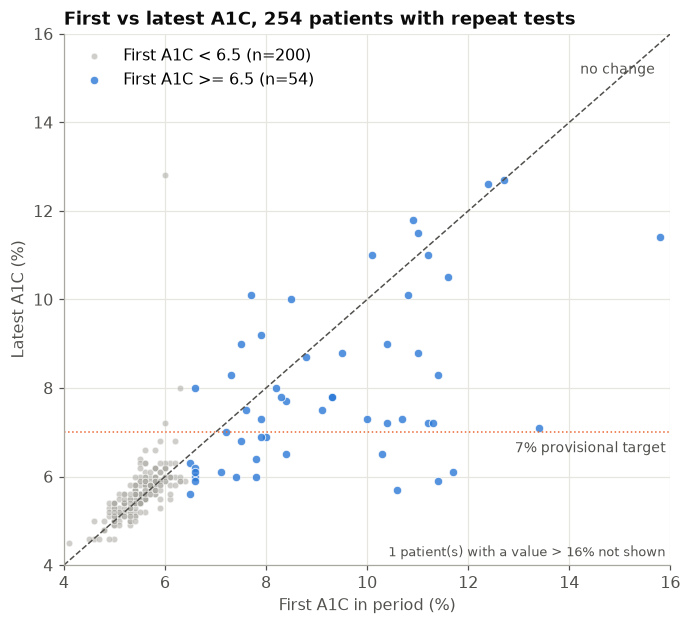

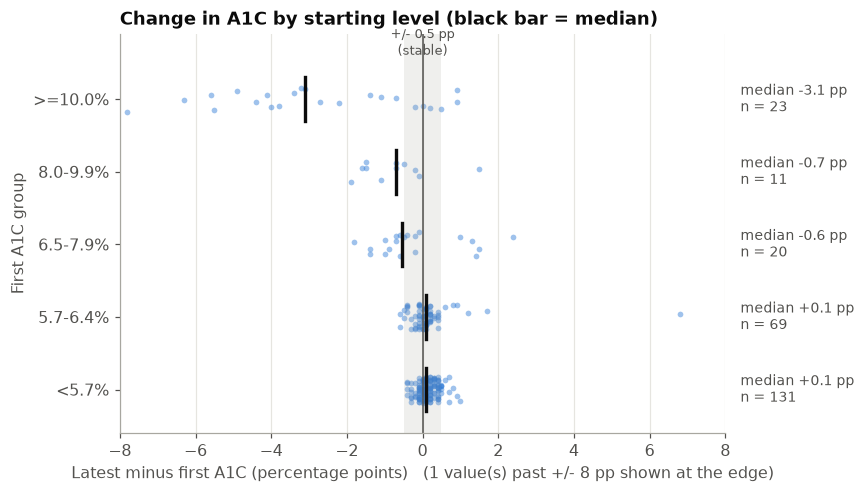

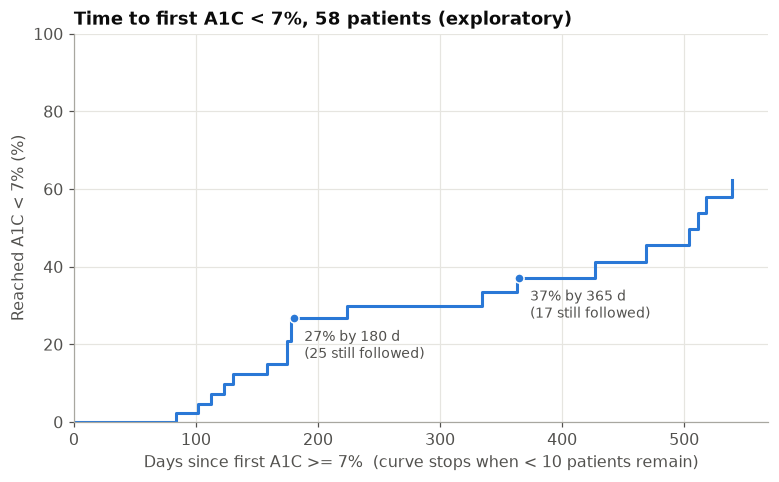

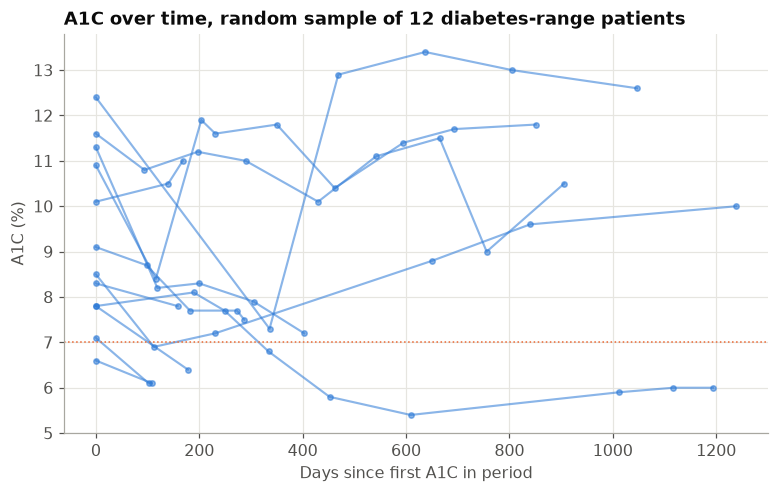

In [11]:
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=200)
    plt.show()

# 1. A1C tests per year
fig, ax = plt.subplots(figsize=(7, 3.8))
x = volume.index.astype(str)
bars = ax.bar(x, volume["a1c_tests"], width=0.55, color=BLUE)
ax.bar_label(bars, labels=[f"{n:,}" for n in volume["a1c_tests"]], padding=3, color=INK_2)
for i, (y, m) in enumerate(volume["months_covered"].items()):
    if m < 11.5:
        ax.text(i, 0, f"{m:.0f} months", ha="center", va="bottom", color="white", fontsize=9)
ax.set(ylabel="A1C tests", title="A1C tests per year")
ax.grid(axis="x", visible=False)
ax.margins(y=0.12)
finish(fig, "01_tests_per_year.png")

# 2. First A1C compared to latest A1C (paired patients)
fig, ax = plt.subplots(figsize=(6.4, 5.8))
other = paired[~paired["diabetes_range_at_baseline"]]
ax.scatter(other["baseline_a1c"], other["latest_a1c"], s=18, color=MUTED, alpha=.55,
           edgecolor="white", linewidth=.5, label=f"First A1C < {DIABETES_RANGE_THRESHOLD} (n={len(other)})")
ax.scatter(dm_paired["baseline_a1c"], dm_paired["latest_a1c"], s=30, color=BLUE, alpha=.8,
           edgecolor="white", linewidth=.6, label=f"First A1C >= {DIABETES_RANGE_THRESHOLD} (n={len(dm_paired)})")
lo, hi = 4, 16
off = paired[(paired[["baseline_a1c", "latest_a1c"]] > hi).any(axis=1)]
ax.plot([lo, hi], [lo, hi], "--", color=INK_2, linewidth=1)
ax.text(hi - .3, hi - .9, "no change", color=INK_2, ha="right", fontsize=9)
ax.axhline(threshold, color=ORANGE, linewidth=1, linestyle=":")
ax.text(hi - .1, threshold - .45, f"{threshold:g}% provisional target", color=INK_2, fontsize=9, ha="right")
if len(off):
    ax.text(hi - .1, lo + .2, f"{len(off)} patient(s) with a value > {hi}% not shown", color=INK_2,
            fontsize=8.5, ha="right")
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="First A1C in period (%)", ylabel="Latest A1C (%)",
       title=f"First vs latest A1C, {len(paired):,} patients with repeat tests")
ax.legend(loc="upper left")
finish(fig, "02_first_vs_latest.png")

# 3. Change by starting group (dots and median)
groups = [g for g in BASELINE_LABELS if (paired["baseline_group"] == g).any()]
XMIN, XMAX = -8, 8
fig, ax = plt.subplots(figsize=(8, 4.6))
rng = np.random.default_rng(7)
n_clipped = 0
for i, g in enumerate(groups):
    vals = paired.loc[paired["baseline_group"] == g, "change_pp"]
    shown = vals.clip(XMIN + .2, XMAX - .2)
    n_clipped += int((shown != vals).sum())
    ax.scatter(shown, i + rng.uniform(-.18, .18, len(vals)), s=14, color=BLUE, alpha=.45, linewidth=0)
    ax.plot([vals.median()] * 2, [i - .3, i + .3], color=INK, linewidth=2.2)
    ax.text(XMAX + .4, i, f"median {vals.median():+.1f} pp\nn = {len(vals)}", va="center",
            fontsize=9, color=INK_2)
ax.axvspan(-tol, tol, color=MUTED, alpha=.18, linewidth=0)
ax.axvline(0, color=INK_2, linewidth=1)
ax.text(0, len(groups) - .45, f"+/- {tol:g} pp\n(stable)", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(groups)), [f"{g}%" for g in groups])
ax.set_ylim(-.6, len(groups) - .1)
ax.set_xlim(XMIN, XMAX)
note = f"   ({n_clipped} value(s) past +/- {XMAX} pp shown at the edge)" if n_clipped else ""
ax.set(xlabel="Latest minus first A1C (percentage points)" + note, ylabel="First A1C group",
       title="Change in A1C by starting level (black bar = median)")
ax.grid(axis="y", visible=False)
finish(fig, "03_change_by_starting_level.png")

# 4. Time to first observed control (Kaplan-Meier, exploratory).
# Stop the curve when fewer than MIN_AT_RISK patients remain. The estimate is not stable after that.
MIN_AT_RISK = 10
t_all = time_to_control["time_days"]
cutoff = max(d for d in range(0, int(t_all.max()) + 1) if t_all.ge(d).sum() >= MIN_AT_RISK)
km_plot = pd.concat([km[km["days"].le(cutoff)],
                     pd.DataFrame({"days": [cutoff], "cumulative_pct_reached_control": [km_at(cutoff)]})])
fig, ax = plt.subplots(figsize=(7.2, 4.5))
ax.step(km_plot["days"], km_plot["cumulative_pct_reached_control"], where="post", color=BLUE, linewidth=2)
for d in (180, 365, 730):
    if d <= cutoff:
        ax.plot(d, km_at(d), "o", color=BLUE, markersize=6, markeredgecolor="white")
        ax.annotate(f"{km_at(d):.0f}% by {d} d\n({at_risk_at(d)} still followed)", (d, km_at(d)),
                    textcoords="offset points", xytext=(7, -26), fontsize=9, color=INK_2)
ax.set(xlim=(0, cutoff + 30), ylim=(0, 100),
       xlabel=f"Days since first A1C >= {threshold:g}%  (curve stops when < {MIN_AT_RISK} patients remain)",
       ylabel=f"Reached A1C < {threshold:g}% (%)",
       title=f"Time to first A1C < {threshold:g}%, {n_initial} patients (exploratory)")
finish(fig, "04_time_to_control.png")

# 5. A1C over time for a random sample of diabetes-range patients
sample_ids = dm_paired.sample(n=min(12, len(dm_paired)), random_state=42).index
traj = clean[clean["patient_id"].isin(sample_ids)].join(patients[["baseline_date"]], on="patient_id")
traj["elapsed_days"] = (traj["date"] - traj["baseline_date"]).dt.days
fig, ax = plt.subplots(figsize=(7.2, 4.6))
for _, line in traj.groupby("patient_id"):
    ax.plot(line["elapsed_days"], line["a1c"], color=BLUE, alpha=.55, linewidth=1.4,
            marker="o", markersize=3.5)
ax.axhline(threshold, color=ORANGE, linewidth=1, linestyle=":")
ax.set(xlabel="Days since first A1C in period", ylabel="A1C (%)",
       title=f"A1C over time, random sample of {len(sample_ids)} diabetes-range patients")
finish(fig, "05_example_trajectories.png")

## 11. Save outputs and settings

The notebook saves the aggregate tables and the settings to `outputs/5.02a/`. It does not save row-level files unless `SAVE_ROW_LEVEL_FILES = True`. Row-level files contain account numbers and dates.

In [12]:
aggregate_outputs = {
    "label_audit": label_audit, "cleaning_counts": cleaning_counts, "testing_volume": volume,
    "tests_per_patient": tests_per_patient_table, "coverage": coverage_table,
    "baseline_distribution": baseline_distribution, "descriptive_change": descriptive,
    "change_by_baseline_group": baseline_comparison, "group_transitions": transition,
    "control_metrics": control_metrics, "prediabetes_progression": prediabetes_progression,
    "repeat_testing": repeat_testing, "km_time_to_control": km,
}
for name, table in aggregate_outputs.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv")

settings = {
    "source_filename": INPUT_FILE.name,
    "start_date": START_DATE, "end_date": END_DATE, "scope": scope,
    "verified_A1C_labels": sorted(A1C_LABELS), "units_confirmed_percent": UNITS_CONFIRMED_PERCENT,
    "settings_are_provisional": SETTINGS_ARE_PROVISIONAL,
    "prediabetes_threshold": PREDIABETES_THRESHOLD, "diabetes_range_threshold": DIABETES_RANGE_THRESHOLD,
    "control_threshold": CONTROL_THRESHOLD, "control_operator": CONTROL_OPERATOR,
    "stability_tolerance_pp": STABILITY_TOLERANCE_PP, "baseline_bins": BASELINE_BINS,
    "baseline_labels": BASELINE_LABELS, "followup_window_days": FOLLOWUP_WINDOW_DAYS,
    "collapse_identical_duplicates": COLLAPSE_IDENTICAL_DUPLICATES,
    "manual_exclusion_reason": EXCLUSION_REASON, "manual_exclude_source_rows": MANUAL_EXCLUDE_ROWS,
    "approved_keep_duplicate_source_rows": APPROVED_KEEP_DUPLICATE_ROWS, "export_notes": EXPORT_NOTES,
}
(OUTPUT_DIR / "methodology_settings.json").write_text(json.dumps(settings, indent=2, default=str), encoding="utf-8")

if SAVE_ROW_LEVEL_FILES:
    clean.to_csv(OUTPUT_DIR / "PRIVATE_clean_measurements.csv", index=False)
    review_log.to_csv(OUTPUT_DIR / "PRIVATE_rows_for_review.csv", index=False)
    patients.to_csv(OUTPUT_DIR / "PRIVATE_patient_summary.csv")
    time_to_control.to_csv(OUTPUT_DIR / "PRIVATE_time_to_control.csv")
print("Saved to:", OUTPUT_DIR.resolve())

Saved to: C:\Users\isaia\workspace\biokind\free_clinic_of_powhatan\clinic_a1c\outputs\5.02a


## 12. Summary

### What the notebook does

1. It loads the 5.02a Lab Results Analysis Report. The report has 55,364 rows, 466 lab attributes, and 596 patients.
2. It keeps the 1,147 rows for Hemoglobin A1C and Hemoglobin A1c.
3. It removes 21 rows. 17 rows are same-day copies of a result. 4 rows are not plain numbers (`>14.0`, `6.3.`, and two clotted samples).
4. It uses the remaining 1,126 A1C results from 519 patients. The results are from 2023-01-05 to 2026-11-12.
5. It compares the first and latest A1C for each patient. It also examines control, the prediabetes range, and repeat testing.

### Main findings

- A1C testing increased each year. The clinic did 186 tests in 2023 and 394 tests in 2026. The 2026 data has only 10.4 months.
- 51% of patients had only one A1C test. For patients with more than one test, the median time between tests was 175 days.
- 62% of patients had a first A1C less than 5.7%. 25% were in the prediabetes range (5.7 to 6.4%).
- 67 patients (13%) had a first A1C of 6.5% or higher. This is the diabetes-range cohort.
- 54 patients in the diabetes-range cohort had a repeat test. Their median A1C went from 8.95% to 7.4%. The median change was -0.8 pp. 63% decreased by more than 0.5 pp, 22% stayed stable, and 15% increased.
- 23 patients had a first A1C of 10% or higher and a repeat test. Their median change was -3.1 pp. But 9 of these 23 patients were still at 10% or higher at their latest test.
- 31% of the diabetes-range cohort had a latest A1C less than 7%.
- 58 patients had a first A1C of 7% or higher. 23 of them later had a result less than 7%. 11 of them had no later test.
- The Kaplan-Meier estimate shows that approximately 37% reached an A1C less than 7% within one year. Only 17 patients were still in follow-up at one year, so this estimate is rough.
- 69 patients in the prediabetes range had a repeat test. 13% of them later had a result of 6.5% or higher. 12% had a latest result less than 5.7%.
- 71% of the diabetes-range cohort had a second test within 183 days. 11% had no second test in the period.

### Limits

- The data contains only lab results. We do not know the diagnoses, medications, or visits. Thus, the diabetes-range cohort is an estimate from lab values.
- Patients with no A1C test are not in the data.
- The baseline is the first test in the export. It is not the start of care.
- The follow-up time is different for each patient.
- Part of the decrease in patients who start high is regression to the mean.
- These results do not show that clinic care caused the changes.

### Next steps

- The clinic must approve the cutpoints in Section 2.
- Check the 4 results that are not plain numbers and the 2 values above 15% (15.8 and 21.8) in the source records.